# Automobile Selling Price Prediction using Random Forest Regression

Team Members:
1. Nethara G - 24CS134
2. Nidarshana P - 24CS135
3. Nivetha C R - 24CS142
4. Priyadharshini K - 24CS155

Department of Computer Science and Engineering,
KPR Institute of Engineering and Technology,
Coimbatore, India

##Problem Statement:
Predicting the selling price of used automobiles is challenging because price depends on multiple factors such as vehicle age, mileage, manufacturer, model, engine characteristics and ownership history. This project develops a machine learning model to predict automobile selling prices using historical automobile data.

##Objective:
To develop and evaluate a Random Forest Regression model for predicting automobile selling prices after appropriate data preprocessing, feature engineering and exploratory analysis.

##Workflow:
Data Loading → Preprocessing → Visualization → Feature Engineering → Feature Selection → Train/Test Split → Random Forest Regression → Evaluation → Results.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.feature_selection import f_regression, mutual_info_regression

import os

pd.set_option("display.max_columns", None)

print("All libraries imported successfully.")

All libraries imported successfully.


## 1. Load the dataset

In [2]:
import os

file_name = "automobile_dataset.csv"

if not os.path.exists(file_name):
    from google.colab import files
    uploaded = files.upload()
    csv_files = [n for n in uploaded.keys() if n.lower().endswith(".csv")]
    if not csv_files:
        raise FileNotFoundError("Please upload automobile_dataset.csv")
    file_name = "automobile_dataset.csv" if "automobile_dataset.csv" in csv_files else csv_files[0]

df = pd.read_csv(file_name)
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())


Saving automobile_dataset.csv to automobile_dataset.csv
Dataset loaded successfully.
Shape: (5500, 18)


,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792


## 2. Dataset inspection

In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes)
print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))


Shape: (5500, 18)

Columns:
['Make', 'Model', 'Year', 'Fuel_Type', 'Transmission', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Accident_History', 'Service_History', 'Color', 'Body_Type', 'Drivetrain', 'Fuel_Efficiency', 'Location', 'Selling_Price']

Data types:


,0
Make,object
Model,object
Year,int64
Fuel_Type,object
Transmission,object
Engine_Size,float64
Mileage,int64
Horsepower,float64
Torque,float64
Owners,int64



Missing values:


,0
Service_History,855
Engine_Size,844
Transmission,827
Accident_History,812
Color,803
Horsepower,800
Torque,799
Fuel_Efficiency,794
Location,782
Make,0


## 3. Preprocessing

In [4]:
clean_df = df.copy()

# Remove duplicates
duplicates = clean_df.duplicated().sum()
clean_df = clean_df.drop_duplicates().reset_index(drop=True)

# Numerical missing values -> median
for col in clean_df.select_dtypes(include=np.number).columns:
    if clean_df[col].isnull().sum() > 0:
        clean_df[col] = clean_df[col].fillna(clean_df[col].median())

# Categorical missing values -> mode
for col in clean_df.select_dtypes(include="object").columns:
    if clean_df[col].isnull().sum() > 0:
        mode = clean_df[col].mode(dropna=True)
        if not mode.empty:
            clean_df[col] = clean_df[col].fillna(mode.iloc[0])

print("Duplicates removed:", duplicates)
print("Remaining missing values:", int(clean_df.isnull().sum().sum()))
print("Cleaned shape:", clean_df.shape)


Duplicates removed: 0
Remaining missing values: 0
Cleaned shape: (5500, 18)


In [5]:
cleaned_file = "cleaned_automobile_dataset.csv"
clean_df.to_csv(cleaned_file, index=False)
print("Saved:", cleaned_file)


Saved: cleaned_automobile_dataset.csv


## 4. Visualization

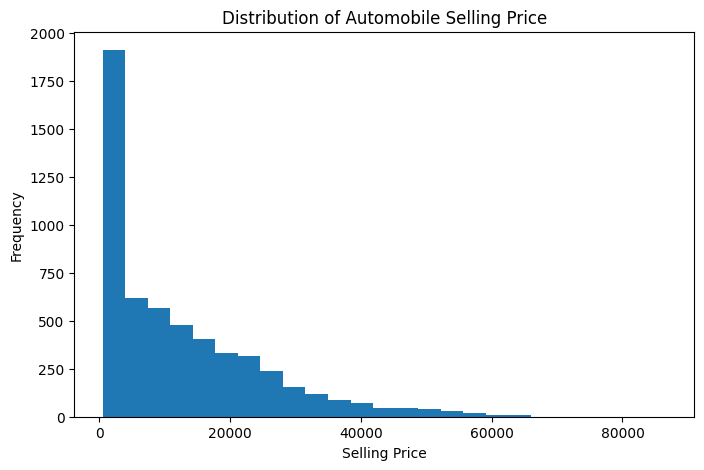

In [6]:
plt.figure(figsize=(8,5))
plt.hist(clean_df["Selling_Price"], bins=25)
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.title("Distribution of Automobile Selling Price")
plt.show()


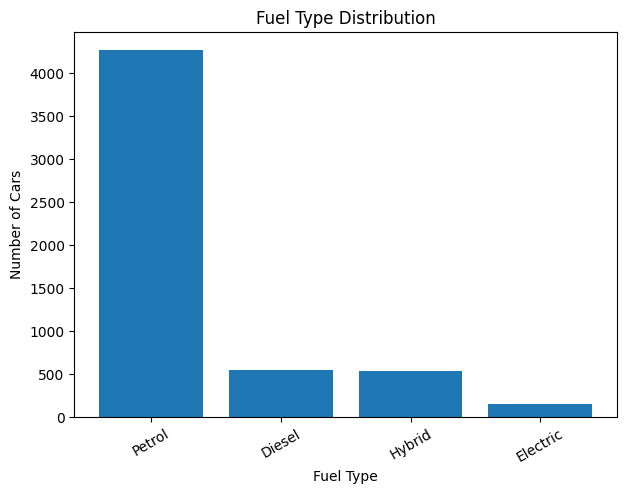

In [7]:
if "Fuel_Type" in clean_df.columns:
    counts = clean_df["Fuel_Type"].value_counts()
    plt.figure(figsize=(7,5))
    plt.bar(counts.index.astype(str), counts.values)
    plt.xlabel("Fuel Type")
    plt.ylabel("Number of Cars")
    plt.title("Fuel Type Distribution")
    plt.xticks(rotation=30)
    plt.show()


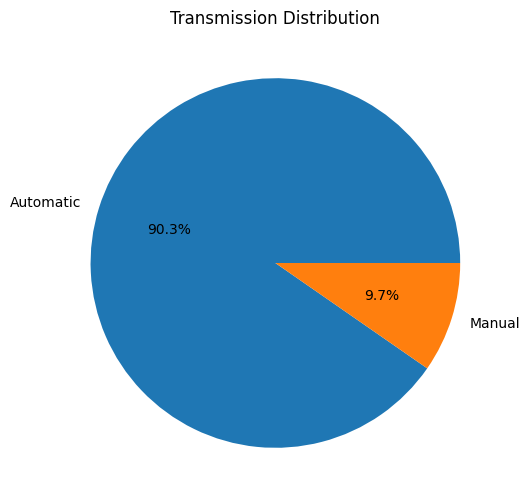

In [8]:
if "Transmission" in clean_df.columns:
    counts = clean_df["Transmission"].value_counts()
    plt.figure(figsize=(6,6))
    plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%")
    plt.title("Transmission Distribution")
    plt.show()


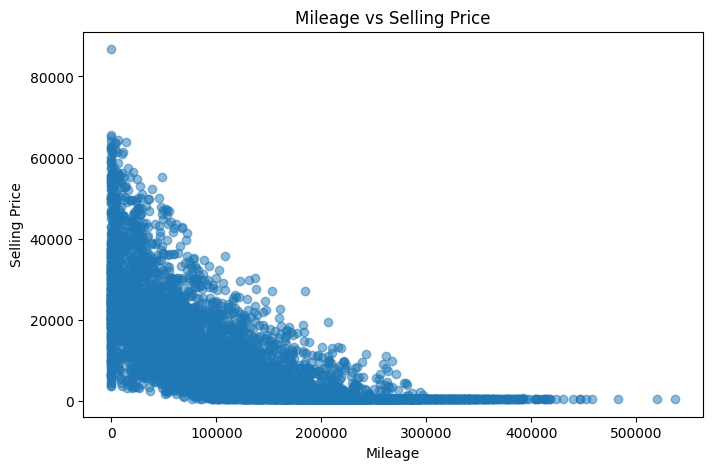

In [9]:
plt.figure(figsize=(8,5))
plt.scatter(clean_df["Mileage"], clean_df["Selling_Price"], alpha=0.5)
plt.xlabel("Mileage")
plt.ylabel("Selling Price")
plt.title("Mileage vs Selling Price")
plt.show()


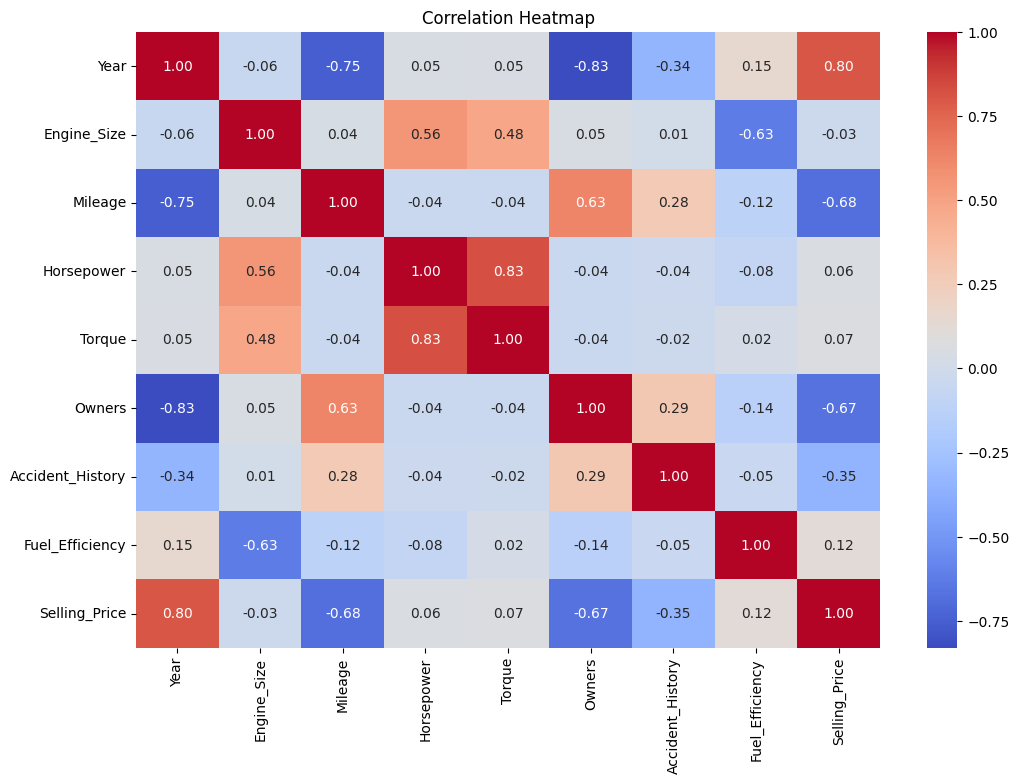

In [10]:
numeric_df = clean_df.select_dtypes(include=np.number)
plt.figure(figsize=(12,8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [11]:
fig = px.scatter(
    clean_df,
    x="Mileage",
    y="Selling_Price",
    color="Fuel_Type" if "Fuel_Type" in clean_df.columns else None,
    hover_data=["Make", "Model"] if {"Make","Model"}.issubset(clean_df.columns) else None,
    title="Interactive Mileage vs Selling Price"
)
fig.show()


## 5. Feature Engineering

`Price_per_HP` is intentionally excluded because it contains `Selling_Price`, the target variable, and would cause target leakage.


In [12]:
ml_df = clean_df.copy()

ml_df["Car_Age"] = datetime.now().year - ml_df["Year"]

ml_df["Mileage_per_Engine"] = (
    ml_df["Mileage"] / ml_df["Engine_Size"].replace(0, np.nan)
)

ml_df["First_Owner"] = (ml_df["Owners"] == 1).astype(int)

ml_df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Feature engineering completed.")
display(ml_df.head())


Feature engineering completed.


,Make,Model,Year,Fuel_Type,Transmission,Engine_Size,Mileage,Horsepower,Torque,Owners,Accident_History,Service_History,Color,Body_Type,Drivetrain,Fuel_Efficiency,Location,Selling_Price,Car_Age,Mileage_per_Engine,First_Owner
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,Full Service,Silver,SUV,AWD,30.0,IL,64140,2,43.478261,1
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,Full Service,Blue,SUV,FWD,35.0,FL,500,18,168276.086957,0
2,Volkswagen,Golf,2021,Hybrid,Automatic,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429,5,24238.947368,1
3,Chevrolet,Tahoe,2005,Petrol,Automatic,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,32.0,FL,2199,21,64228.181818,0
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792,4,17270.000000,1


## 6. Regression Feature Selection

The target is continuous (`Selling_Price`), so regression-based feature selection is used. Categorical values are factorized only for this analysis.


In [13]:
fs_df = ml_df.copy()

for col in fs_df.select_dtypes(include="object").columns:
    fs_df[col] = pd.factorize(fs_df[col])[0]

fs_df = fs_df.apply(pd.to_numeric, errors="coerce")
fs_df = fs_df.replace([np.inf, -np.inf], np.nan)
fs_df = fs_df.fillna(fs_df.median(numeric_only=True))

X_fs = fs_df.drop(columns=["Selling_Price"]).select_dtypes(include=np.number)
y_fs = fs_df["Selling_Price"]

print("Feature-selection matrix:", X_fs.shape)


Feature-selection matrix: (5500, 20)


In [14]:
corr = fs_df.corr(numeric_only=True)["Selling_Price"].drop("Selling_Price")
corr_results = corr.abs().sort_values(ascending=False).to_frame("Absolute Correlation")
display(corr_results.head(10))


,Absolute Correlation
Car_Age,0.804933
Year,0.804933
Mileage,0.682883
First_Owner,0.682265
Owners,0.669046
Mileage_per_Engine,0.630522
Accident_History,0.347294
Transmission,0.243412
Fuel_Type,0.132468
Fuel_Efficiency,0.118963


In [15]:
# f_regression is imported in the first cell.
f_scores, f_pvalues = f_regression(X_fs, y_fs)

f_results = pd.DataFrame({
    "Feature": X_fs.columns,
    "F Score": f_scores,
    "p-value": f_pvalues
}).sort_values("F Score", ascending=False)

display(f_results.head(10))


,Feature,F Score,p-value
17,Car_Age,10117.629328,0.000000e+00
2,Year,10117.629328,0.000000e+00
6,Mileage,4804.220023,0.000000e+00
19,First_Owner,4787.966858,0.000000e+00
9,Owners,4455.343134,0.000000e+00
18,Mileage_per_Engine,3628.184590,0.000000e+00
10,Accident_History,754.083702,1.099599e-155
4,Transmission,346.270248,5.314725e-75
3,Fuel_Type,98.200238,5.884102e-23
15,Fuel_Efficiency,78.925259,8.600369e-19


In [16]:
mi_scores = mutual_info_regression(X_fs, y_fs, random_state=42)

mi_results = pd.DataFrame({
    "Feature": X_fs.columns,
    "MI Score": mi_scores
}).sort_values("MI Score", ascending=False)

display(mi_results.head(10))


,Feature,MI Score
2,Year,0.723398
17,Car_Age,0.719985
6,Mileage,0.587521
18,Mileage_per_Engine,0.527912
9,Owners,0.398481
19,First_Owner,0.302089
1,Model,0.115194
0,Make,0.089351
10,Accident_History,0.067075
4,Transmission,0.054742


## 7. Define X and y

In [17]:
X = ml_df.drop(columns=["Selling_Price"])
y = ml_df["Selling_Price"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target: Selling_Price")


X shape: (5500, 20)
y shape: (5500,)
Target: Selling_Price


## 8. Train/Test Split

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 4400
Testing samples: 1100


## 9. Preprocessing Pipeline

Random Forest does not require feature scaling. Numerical columns use median imputation; categorical columns use most-frequent imputation and One-Hot Encoding.


In [19]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include="object").columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)


Numerical features: ['Year', 'Engine_Size', 'Mileage', 'Horsepower', 'Torque', 'Owners', 'Accident_History', 'Fuel_Efficiency', 'Car_Age', 'Mileage_per_Engine', 'First_Owner']
Categorical features: ['Make', 'Model', 'Fuel_Type', 'Transmission', 'Service_History', 'Color', 'Body_Type', 'Drivetrain', 'Location']


## 10. Random Forest Regression

In [20]:
model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])

model_pipeline.fit(X_train, y_train)
print("Random Forest Regression model trained successfully.")


Random Forest Regression model trained successfully.


## 11. Predictions and Evaluation

In [21]:
y_pred = model_pipeline.predict(X_test)

prediction_results = pd.DataFrame({
    "Actual_Selling_Price": y_test.values,
    "Predicted_Selling_Price": y_pred
})

display(prediction_results.head(10))


,Actual_Selling_Price,Predicted_Selling_Price
0,3837,4162.360
1,500,500.000
2,10127,12049.585
3,5357,7604.300
4,18121,19539.100
5,18875,19764.545
6,8926,7864.575
7,857,1079.420
8,5886,6450.820
9,31208,24823.795


In [22]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("=" * 50)
print("RANDOM FOREST REGRESSION RESULTS")
print("=" * 50)
print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")
print("=" * 50)


RANDOM FOREST REGRESSION RESULTS
MAE  : 1349.7979
RMSE : 2113.4888
R²   : 0.9716


## 12. Actual vs Predicted

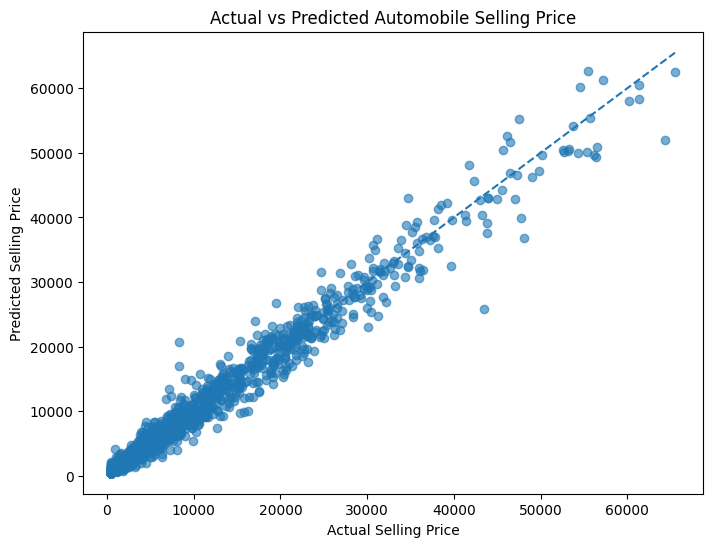

In [23]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.6)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Selling Price")
plt.ylabel("Predicted Selling Price")
plt.title("Actual vs Predicted Automobile Selling Price")
plt.show()


## 13. Residual Plot

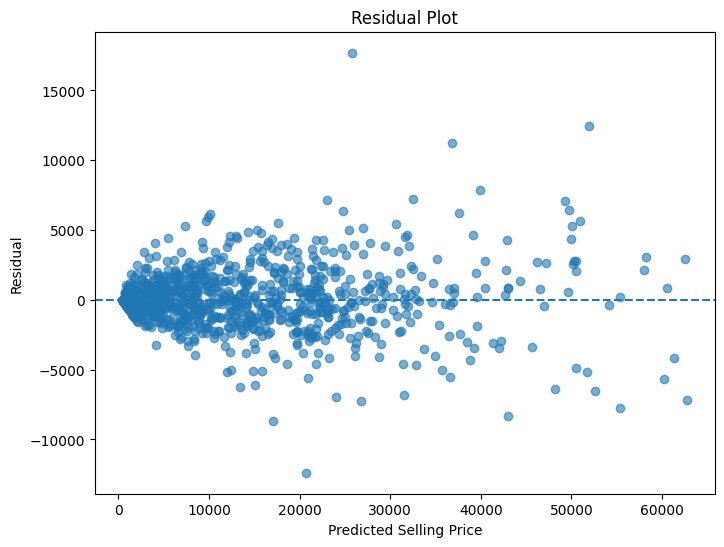

In [24]:
residuals = y_test - y_pred

plt.figure(figsize=(8,6))
plt.scatter(y_pred, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.show()


## 14. Feature Importance

In [25]:
fitted_preprocessor = model_pipeline.named_steps["preprocessor"]
fitted_model = model_pipeline.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": fitted_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance.head(15))


,Feature,Importance
8,num__Car_Age,0.348681
0,num__Year,0.346601
17,cat__Make_Mercedes-Benz,0.058398
12,cat__Make_BMW,0.057547
11,cat__Make_Audi,0.055607
2,num__Mileage,0.026466
9,num__Mileage_per_Engine,0.019086
56,cat__Model_Tahoe,0.016137
81,cat__Body_Type_Sedan,0.012236
40,cat__Model_GLE,0.007298


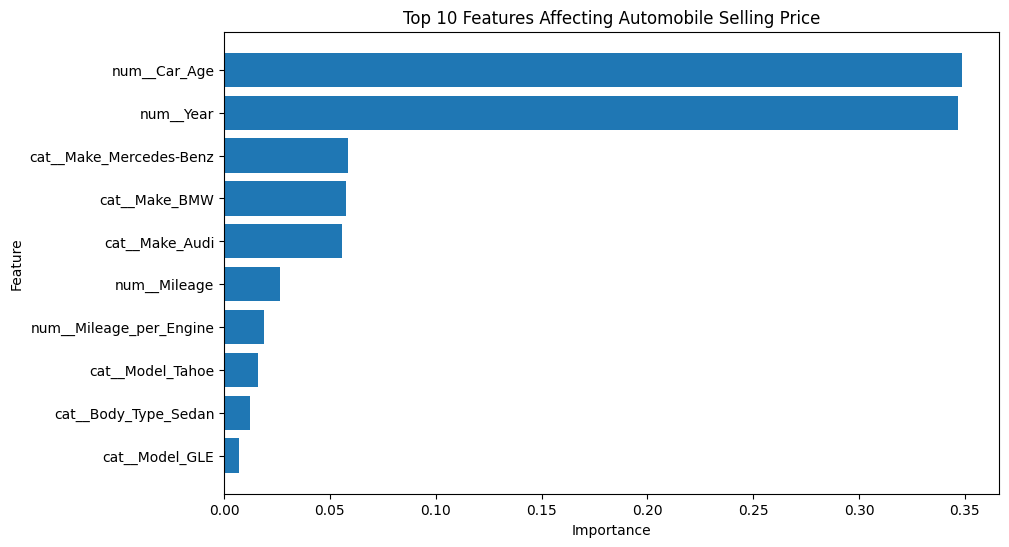

In [26]:
top_features = importance.head(10).sort_values("Importance")

plt.figure(figsize=(10,6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Affecting Automobile Selling Price")
plt.show()


## 15. Comparative Evaluation of Regression Models

To determine the most suitable regression approach, three models are evaluated on the same test set:

1. Linear Regression
2. Decision Tree Regression
3. Random Forest Regression

MAE, RMSE, and R² are used for comparison. Lower MAE and RMSE indicate lower prediction error, while a higher R² indicates better explanatory performance.


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Linear Regression
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_pred)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
linear_r2 = r2_score(y_test, linear_pred)

print("Linear Regression")
print(f"MAE  : {linear_mae:.4f}")
print(f"RMSE : {linear_rmse:.4f}")
print(f"R²   : {linear_r2:.4f}")

Linear Regression
MAE  : 3407.3696
RMSE : 4638.8543
R²   : 0.8633


## 16. Decision Tree Regression

In [28]:
decision_tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        random_state=42,
        max_depth=10
    ))
])

decision_tree_model.fit(X_train, y_train)

tree_pred = decision_tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_pred)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_pred))
tree_r2 = r2_score(y_test, tree_pred)

print("Decision Tree Regression")
print(f"MAE  : {tree_mae:.4f}")
print(f"RMSE : {tree_rmse:.4f}")
print(f"R²   : {tree_r2:.4f}")

Decision Tree Regression
MAE  : 1998.5798
RMSE : 3128.9563
R²   : 0.9378


## 17. Final Model Comparison

In [29]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        linear_mae,
        tree_mae,
        mae
    ],
    "RMSE": [
        linear_rmse,
        tree_rmse,
        rmse
    ],
    "R2": [
        linear_r2,
        tree_r2,
        r2
    ]
})

comparison = comparison.sort_values(
    by="R2",
    ascending=False
).reset_index(drop=True)

display(comparison)

,Model,MAE,RMSE,R2
0,Random Forest Regression,1349.797891,2113.488803,0.971626
1,Decision Tree Regression,1998.579761,3128.956280,0.937811
2,Linear Regression,3407.369630,4638.854272,0.863310


## 18. Comparison of Regression Models

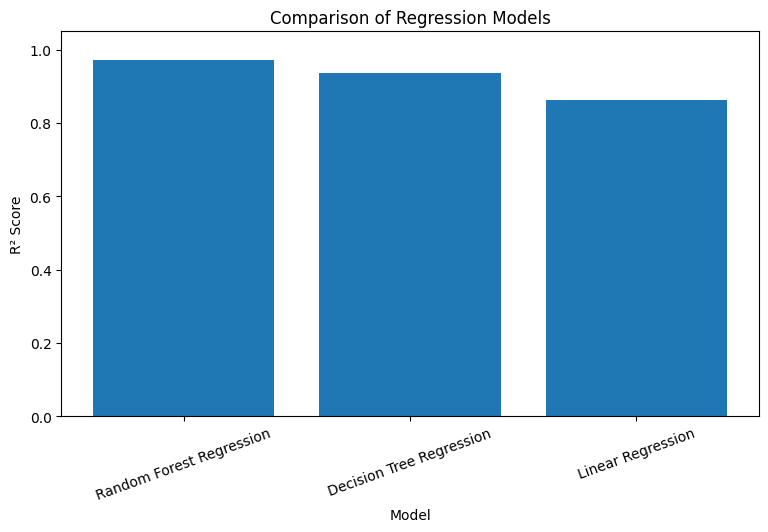

In [30]:
plt.figure(figsize=(9,5))

plt.bar(
    comparison["Model"],
    comparison["R2"]
)

plt.xlabel("Model")
plt.ylabel("R² Score")
plt.title("Comparison of Regression Models")

plt.xticks(rotation=20)
plt.ylim(0, 1.05)

plt.show()

##19. MAE and RMSE Comparison

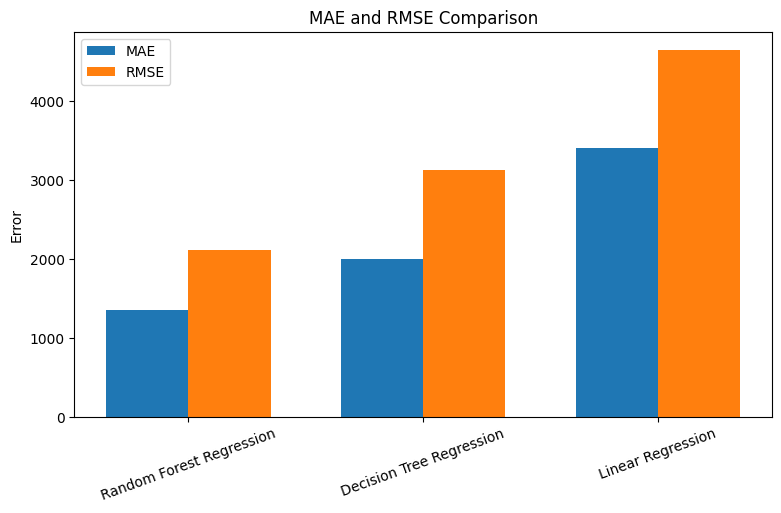

In [31]:
plt.figure(figsize=(9,5))

x = np.arange(len(comparison))
width = 0.35

plt.bar(
    x - width/2,
    comparison["MAE"],
    width,
    label="MAE"
)

plt.bar(
    x + width/2,
    comparison["RMSE"],
    width,
    label="RMSE"
)

plt.xticks(x, comparison["Model"], rotation=20)
plt.ylabel("Error")
plt.title("MAE and RMSE Comparison")
plt.legend()

plt.show()

## 20. Model Comparison Discussion

Three regression models were evaluated for automobile selling-price prediction. Random Forest Regression achieved the best performance with an MAE of **1349.797891**, an RMSE of **2113.488803**, and an R² of **0.971626**.

Decision Tree Regression achieved an MAE of **1998.579761**, an RMSE of **3128.956280**, and an R² of **0.937811**, while Linear Regression achieved an MAE of **3407.369630**, an RMSE of **4638.854272**, and an R² of **0.863310**.

Therefore, Random Forest Regression is selected as the best-performing model because it produced the lowest MAE and RMSE and the highest R² among the three evaluated approaches. The comparison demonstrates that the ensemble model captures the nonlinear relationships in the automobile attributes more effectively than the two baseline models.


## 21. Saving Experimental Results

The model predictions and evaluation metrics are saved as CSV files. These files provide a reproducible record of the experimental results for reporting and further analysis.


In [32]:
prediction_file = "automobile_price_predictions.csv"
metrics_file = "automobile_model_metrics.csv"

prediction_results.to_csv(prediction_file, index=False)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2"],
    "Value": [mae, rmse, r2]
})
metrics.to_csv(metrics_file, index=False)

print("Saved:", prediction_file)
print("Saved:", metrics_file)
display(metrics)

Saved: automobile_price_predictions.csv
Saved: automobile_model_metrics.csv


,Metric,Value
0,MAE,1349.797891
1,RMSE,2113.488803
2,R2,0.971626


# 22. Conclusion

This study developed a machine learning framework for automobile selling-price prediction using historical automobile data. The workflow included data preprocessing, exploratory data analysis, feature engineering, regression-based feature selection, and comparative evaluation of regression models.

Linear Regression, Decision Tree Regression, and Random Forest Regression were evaluated using MAE, RMSE, and R². Random Forest Regression achieved the best performance, with an MAE of **1349.797891**, an RMSE of **2113.488803**, and an R² of **0.971626**.

The results demonstrate that Random Forest is effective for modeling the nonlinear relationships between automobile characteristics and selling price. Feature-importance analysis also provides insight into the attributes contributing most strongly to the predictions.

The developed framework can serve as a foundation for automobile price estimation and decision-support applications. Future work can investigate larger and more diverse datasets, hyperparameter optimization, additional ensemble methods, and deployment as a real-time prediction application.